# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import GLHWaterDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 250


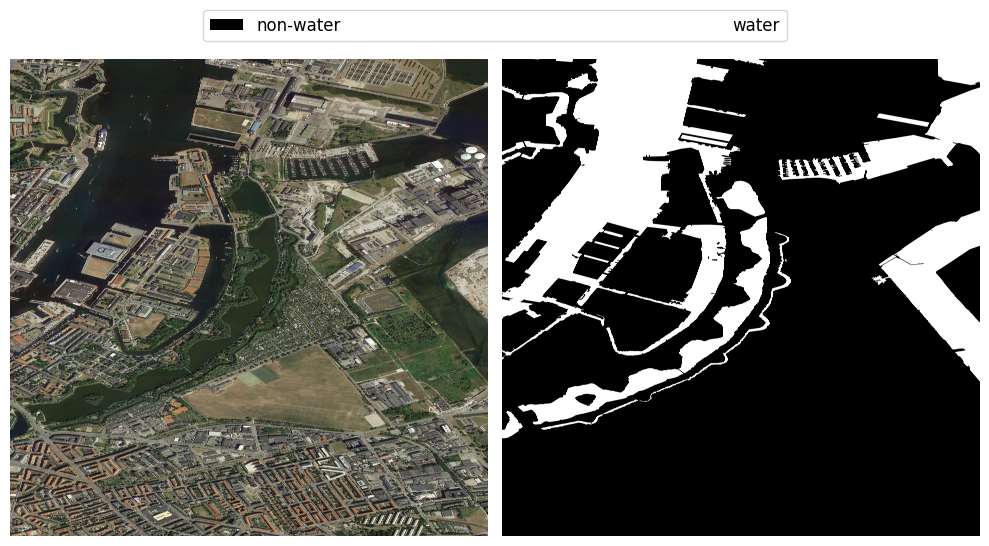

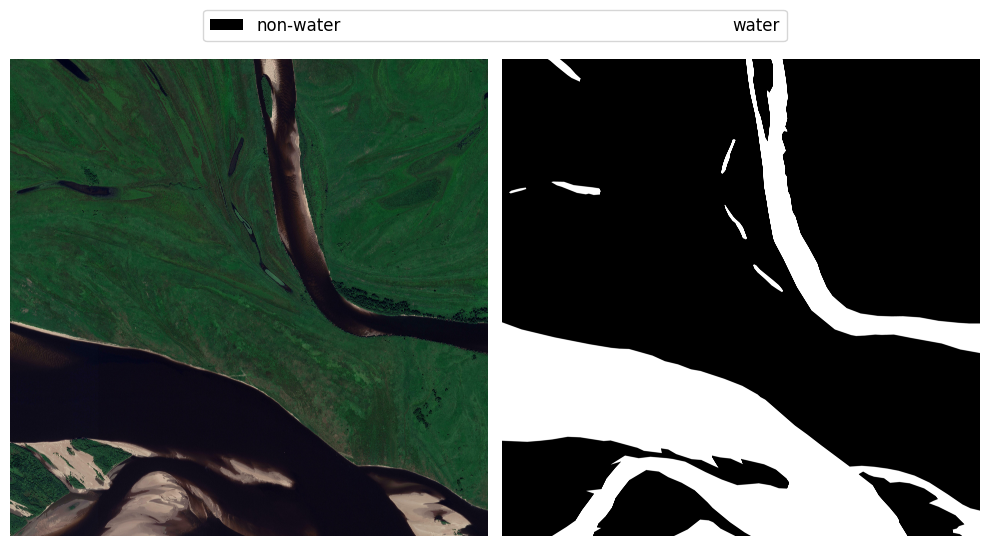

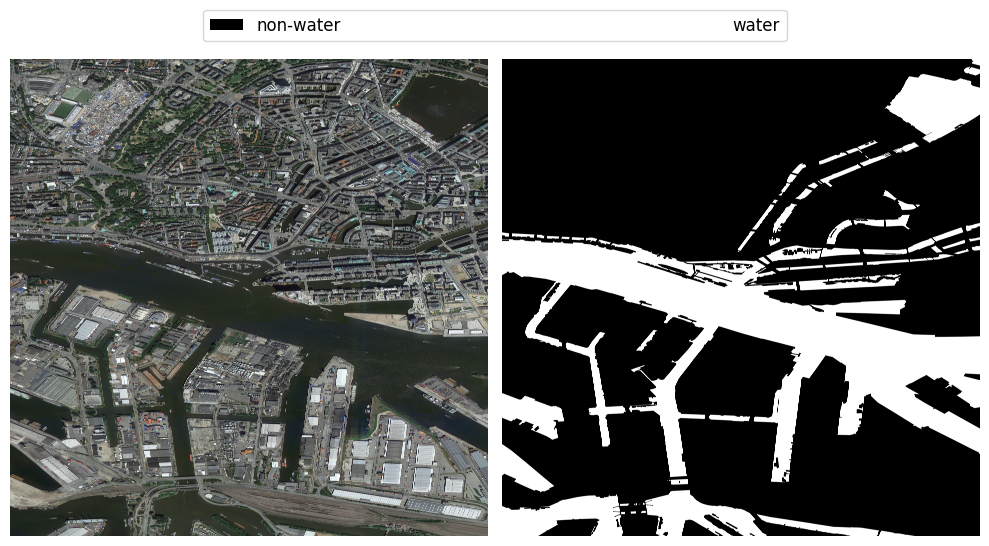

In [6]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/GLH_Water"
}
dataset = GLHWaterDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(100);

In [7]:
dataset.data_distribution_table()

,Number of pixels
non-water,3.471982e+10
water,6.240182e+09


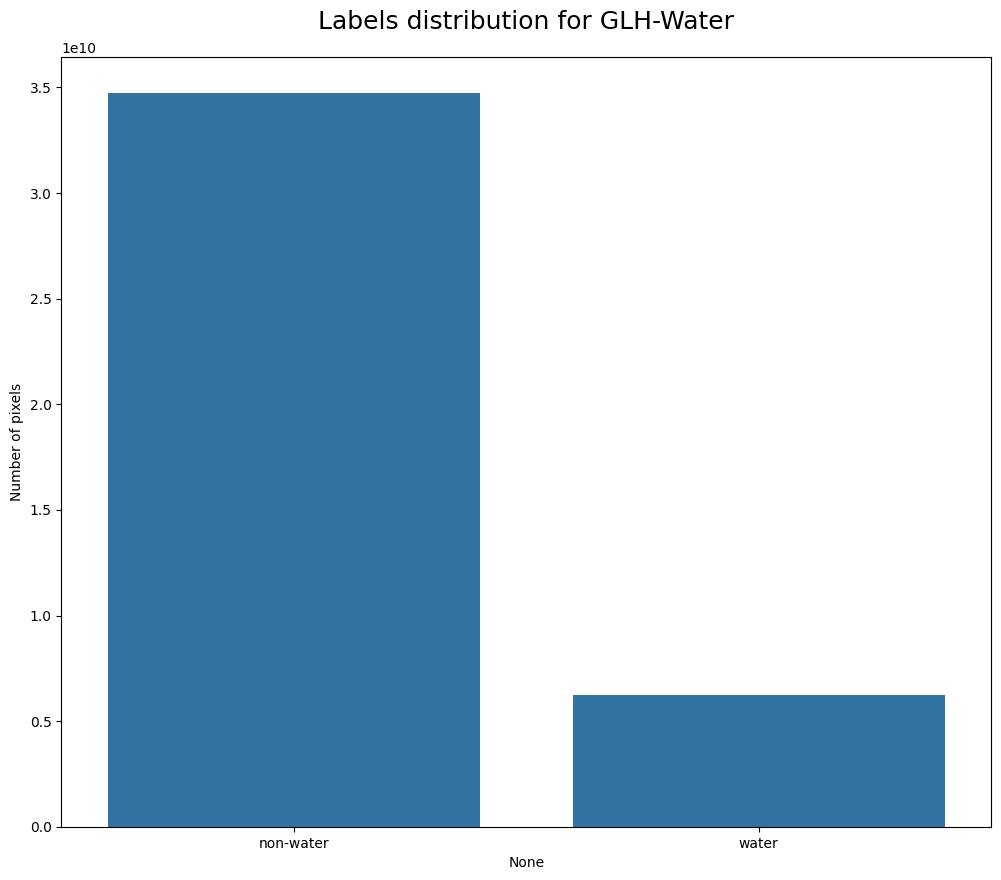

In [8]:
dataset.data_distribution_barchart();

## Load training data

In [9]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/GLH_Water/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = GLHWaterDataset(train_dataset_config)
len(train_dataset)

200

## Create the model

In [12]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/GLH_Water"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [13]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-31 07:19:34,642 INFO Starting training.
training: 100%|██████████| 25/25 [6:59:29<00:00, 1006.78s/it]  
2025-03-31 14:19:04,290 INFO epoch: 1, time: 25170, loss:  0.42950
testing on train set: 100%|██████████| 25/25 [7:01:03<00:00, 1010.55s/it]  
2025-03-31 21:20:09,720 INFO IOU:0.6397874217208585, IOU mean:0.5427959805691619, IOU per Class:[0.74877984 0.33681212]
training: 100%|██████████| 25/25 [7:00:10<00:00, 1008.41s/it]  
2025-04-01 04:20:19,876 INFO epoch: 2, time: 25210, loss:  0.32633
testing on train set: 100%|██████████| 25/25 [7:01:12<00:00, 1010.89s/it]  
2025-04-01 11:21:32,051 INFO IOU:0.7936309109883817, IOU mean:0.6849484072372104, IOU per Class:[0.87546725 0.49442956]
training: 100%|██████████| 25/25 [7:05:04<00:00, 1020.18s/it]  
2025-04-01 18:26:36,607 INFO epoch: 3, time: 25504, loss:  0.27819
testing on train set: 100%|██████████| 25/25 [7:00:46<00:00, 1009.84s/it]  
2025-04-02 01:27:22,713 INFO IOU:0.8209596663012131, IOU mean:0.7078986374983695, IOU per C

## Evaluate the model

In [14]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/GLH_Water/val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = GLHWaterDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

25


2025-04-03 06:28:22,417 INFO Loading checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar
2025-04-03 06:28:22,914 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 7/7 [1:00:15<00:00, 516.48s/it] 


[{'IOU': 0.8293108480979892,
  'IOU mean': 0.6901733707477143,
  'IOU per Class': array([0.91317943, 0.46716731])}]

## Predictions

2025-04-03 07:46:28,269 INFO Loading checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar
2025-04-03 07:46:28,728 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar at epoch 6


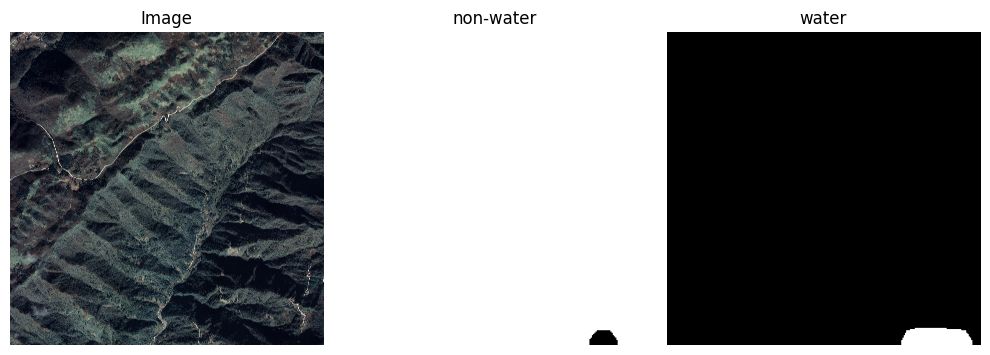

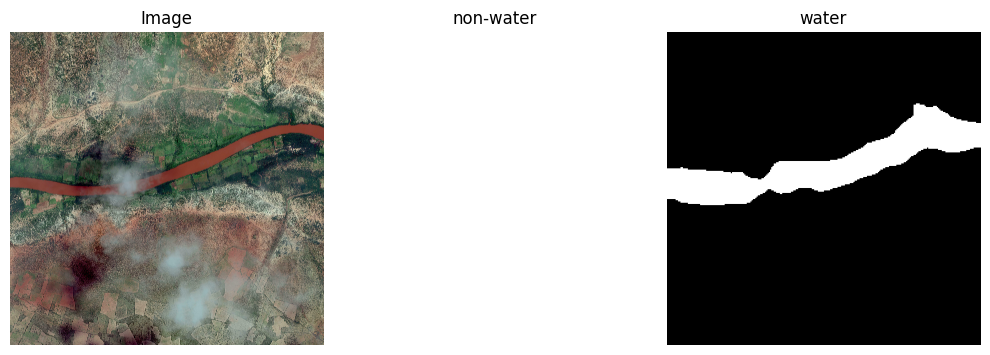

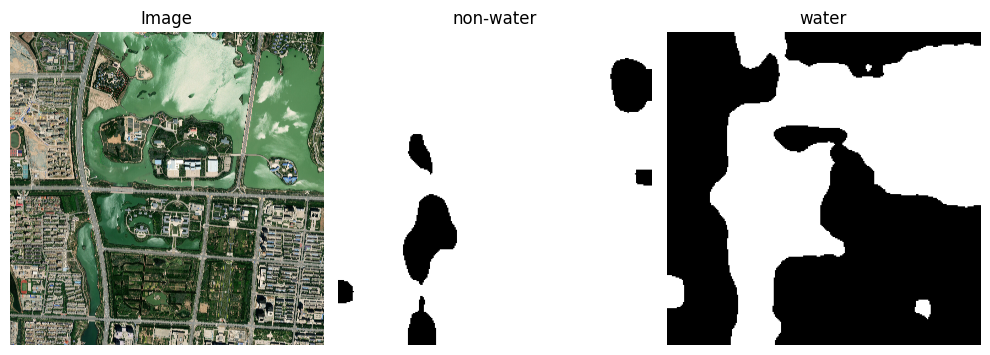

In [17]:
model_path = "/home/dragik/data/FAIR_EO/GLH_Water/checkpoint.pth.tar"
labels = ["non-water","water"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/GLH_Water/test/img/22.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/GLH_Water/test/img/119.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/GLH_Water/test/img/162.jpg')
fig = model.predict_masks(image, labels, transform)